# Thread descriptives by city

Reads the CSV outputs of `02_calculate_thread_stats.py`. The notebook does not modify the database.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
OUTPUT_DIR = Path("/mnt/common-hdd/group-dirs/twitter-2025-project/thread_statistics")

summary = pd.read_csv(OUTPUT_DIR / "city_summary.csv")
display(summary)

,city,n_conversations,n_observed_tweets,n_singletons,n_multi_tweet,n_multi_user,n_root_observed,n_root_reconstructed,n_with_retweets
0,amsterdam,17717944,20936901.0,16072643,1645301,166691,13246589,1952,2528
1,london,107353003,129941246.0,96267821,11085182,1556904,80607093,4257,4580
2,portland,14166116,16022182.0,13178979,987137,91479,11259524,130,162


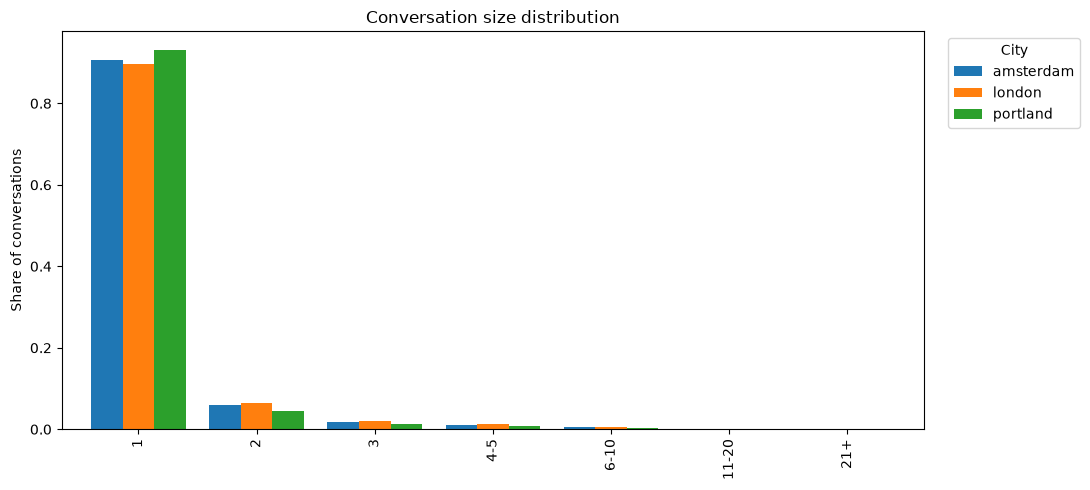

In [2]:
def plot_distribution(filename, title, order):
    df = pd.read_csv(OUTPUT_DIR / filename)
    df["share"] = df["n_conversations"] / df.groupby("city")["n_conversations"].transform("sum")
    pivot = df.pivot(index="category", columns="city", values="share").reindex(order).fillna(0)
    ax = pivot.plot.bar(figsize=(11, 5), width=0.8)
    ax.set(title=title, xlabel="", ylabel="Share of conversations")
    ax.legend(title="City", bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

plot_distribution("thread_size_distribution.csv", "Conversation size distribution", ["1","2","3","4-5","6-10","11-20","21+"])

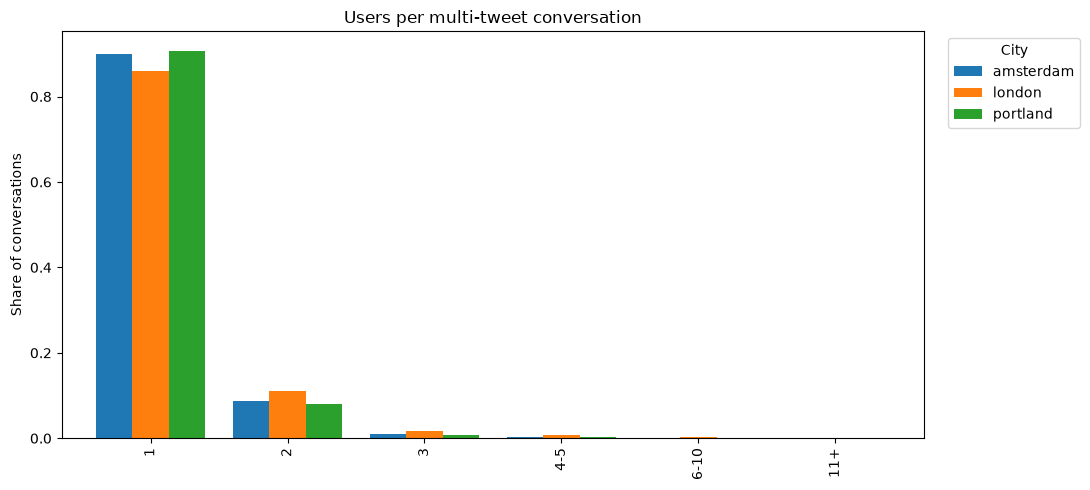

In [3]:
plot_distribution("users_per_multi_tweet_conversation.csv", "Users per multi-tweet conversation", ["1","2","3","4-5","6-10","11+"])

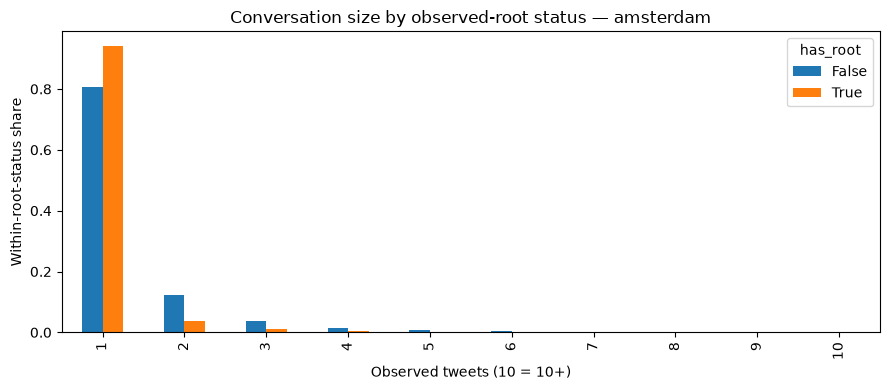

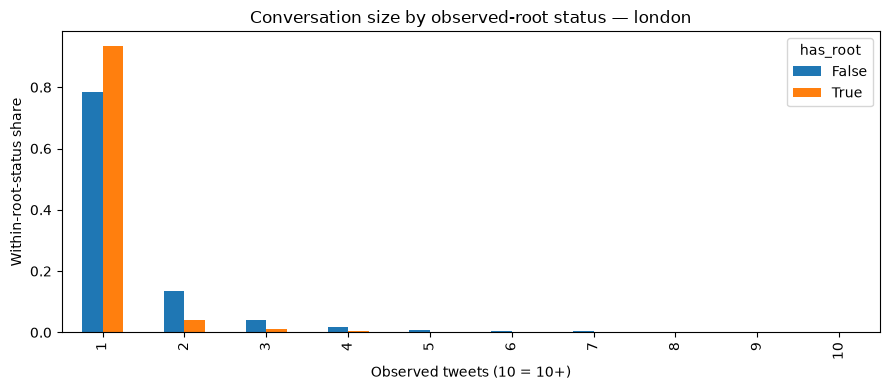

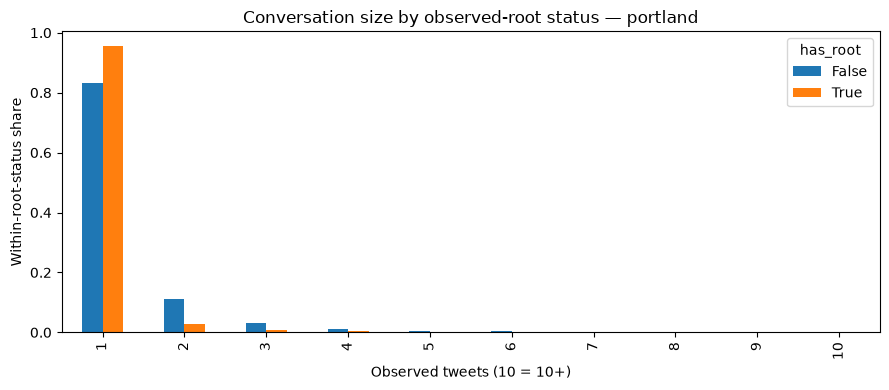

In [4]:
root = pd.read_csv(OUTPUT_DIR / "root_by_thread_size.csv")
root["share"] = root["n_conversations"] / root.groupby(["city", "has_root"])["n_conversations"].transform("sum")
for city, group in root.groupby("city"):
    p = group.pivot(index="observed_tweets_capped", columns="has_root", values="share").fillna(0)
    ax = p.plot.bar(figsize=(9,4), title=f"Conversation size by observed-root status — {city}")
    ax.set(xlabel="Observed tweets (10 = 10+)", ylabel="Within-root-status share")
    plt.tight_layout()
    plt.show()

In [5]:
display(pd.read_csv(OUTPUT_DIR / "root_text_sources.csv"))
display(pd.read_csv(OUTPUT_DIR / "duration_distribution.csv"))

,city,root_text_source,n_conversations
0,amsterdam,observed,13246589
1,amsterdam,retweet,1952
2,amsterdam,unavailable,4469403
3,london,observed,80607093
4,london,retweet,4257
5,london,unavailable,26741653
6,portland,observed,11259524
7,portland,retweet,130
8,portland,unavailable,2906462


,city,median_minutes,p90_minutes,p99_minutes
0,amsterdam,0.0,0.0,766.950000
1,london,0.0,0.7,1044.066667
2,portland,0.0,0.0,478.316667
